# Probability and Uncertainty

No two measurements are identical, no two components have the same lifetime, and every estimate computed from a sample would come out slightly differently with another sample. Engineers deal with this variability every day – in tolerances, safety factors, reliability targets and maintenance plans. Probability theory provides the language to describe it, and statistics provides the tools to quantify how certain our estimates are.

In this chapter we model the lifetimes of jet engines with a probability distribution, derive reliability figures such as the B10 life, and quantify the uncertainty of our estimates with confidence intervals – computed both with a classical formula and with the bootstrap. Finally we meet Bayes' theorem, which tells us how to update probabilities when new information arrives.

::: {.scenario}
**Scenario: the replacement interval**

You are the reliability engineer of an airline that operates a fleet of turbofan engines of one type. The airworthiness authority requires a maintenance programme in which, with 95 % confidence, at most 10 % of the engines reach a critical degradation state before they are taken off wing for overhaul. Your data: the complete run-to-failure histories of 100 engines of the same type. The fleet manager wants the interval as long as possible – every additional cycle on wing saves money.

**Your decision:** After how many flight cycles should engines be overhauled preventively?
:::

**Learning goals.** After this chapter you can

- describe random quantities with probability density, distribution function, expected value and variance,
- choose suitable distributions for engineering data (normal, lognormal, Weibull, exponential),
- fit a distribution to lifetime data by maximum likelihood and check the fit with a probability plot,
- interpret the Weibull shape parameter in terms of failure behaviour and derive the B10 life,
- compute and correctly interpret confidence intervals, analytically and with the bootstrap,
- apply Bayes' theorem to diagnostic alarms and explain the base rate effect,
- (extension) update prior knowledge with test data (beta–binomial model) and interpret a credible interval.

**Datasets in this chapter**

- [NASA C-MAPSS turbofan degradation data](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data)

## Random variables and distributions

::: {.callout-note}
## Definition: Random variable, PDF and CDF
A **random variable** $X$ assigns a number to the outcome of a random experiment, e.g. the lifetime of a component. For a continuous random variable,

- the **cumulative distribution function (CDF)** $F(x) = P(X \le x)$ gives the probability of a value up to $x$,
- the **probability density function (PDF)** $f(x) = F'(x)$ describes how probability is distributed; $P(a < X \le b) = \int_a^b f(x)\,dx$.

The **expected value** $E[X] = \int x\,f(x)\,dx$ is the long-run average, the **variance** $\text{Var}(X) = E[(X - E[X])^2]$ measures the spread.
:::

In reliability engineering, $F(t)$ is the probability that a component has failed by time $t$, and the **reliability** (survival function) is $R(t) = 1 - F(t)$.

Choosing a distribution is a modelling decision, guided by physics and by the data:

| Distribution | Parameters | Typical use | Physical reasoning |
| --- | --- | --- | --- |
| Normal | $\mu$, $\sigma$ | measurement errors, machined dimensions | sum of many small independent effects |
| Lognormal | $\mu$, $\sigma$ of $\ln X$ | fatigue life, particle sizes, repair times | product of many small independent effects |
| Weibull | shape $\beta$, scale $\eta$ | lifetimes, strength of brittle materials | "weakest link": the first of many flaws fails |
| Exponential | rate $\lambda$ | random failures, times between events | constant failure rate, no memory |
| Poisson | rate $\lambda$ | number of defects per unit or per time | rare independent events |

The prominence of the normal distribution is explained by one of the most important results of probability theory:

::: {.callout-important}
## Theorem: Central limit theorem
Let $X_1, \dots, X_n$ be independent random variables with the same distribution, mean $\mu$ and finite variance $\sigma^2$. Then the distribution of the sample mean $\bar X_n$ approaches a normal distribution with mean $\mu$ and standard deviation $\sigma/\sqrt{n}$ as $n$ grows – **whatever the distribution of the $X_i$**.
:::

Two consequences matter for engineers: quantities that arise as sums of many small effects are approximately normal, and the uncertainty of a mean decreases with $1/\sqrt{n}$ – four times as many measurements halve the uncertainty.

## The Weibull distribution for lifetimes

The two-parameter Weibull distribution has the CDF and the **hazard rate** (instantaneous failure rate of the survivors)

$$F(t) = 1 - \exp\left[-\left(\frac{t}{\eta}\right)^{\beta}\right], \qquad h(t) = \frac{f(t)}{R(t)} = \frac{\beta}{\eta}\left(\frac{t}{\eta}\right)^{\beta - 1}.$$

The scale parameter $\eta$ is the **characteristic life**: by $t = \eta$, 63.2 % of all units have failed, regardless of $\beta$. The shape parameter $\beta$ determines how the failure rate changes over time:

::: {.callout-important}
## Interpretation of the Weibull shape parameter
- $\beta < 1$: decreasing failure rate – **early failures** (manufacturing defects, infant mortality).
- $\beta = 1$: constant failure rate – **random failures**; the Weibull becomes the exponential distribution.
- $\beta > 1$: increasing failure rate – **wear-out** (fatigue, corrosion, abrasion). $\beta \approx 3.5$ gives a nearly symmetric distribution.

Together, the three regimes form the well-known *bathtub curve* of a product's life.
:::

![Left: Weibull hazard rate for different shape parameters. Right: the bathtub curve of a product's life as the superposition of early failures, random failures and wear-out.](images/bathtub.png){#fig-bathtub width=100%}

The shape parameter has direct consequences for maintenance: preventive replacement only makes sense if the failure rate increases ($\beta > 1$). With $\beta \le 1$, a new part is not more reliable than an old one, and replacing it early wastes money.

A frequently used reliability figure is the **B10 life**: the time by which 10 % of the units have failed, i.e. $F(B_{10}) = 0.1$. Solving the Weibull CDF gives

$$B_{10} = \eta\,\left(-\ln 0.9\right)^{1/\beta}.$$

### Estimating parameters: maximum likelihood

::: {.callout-note}
## Definition: Maximum likelihood estimation (MLE)
Given independent observations $x_1, \dots, x_n$ and a model with density $f(x;\theta)$, the **likelihood** $L(\theta) = \prod_i f(x_i;\theta)$ measures how plausible the data are for a parameter value $\theta$. The maximum likelihood estimate $\hat\theta$ maximises $L$, in practice its logarithm $\ell(\theta) = \sum_i \ln f(x_i;\theta)$.
:::

For the normal distribution, MLE leads to the familiar mean and (biased) standard deviation. For the Weibull distribution, there is no closed-form solution; `scipy.stats.weibull_min.fit` maximises the likelihood numerically.

To check whether the fitted distribution describes the data, we use a **probability plot** (Q–Q plot): the sorted data are plotted against the corresponding quantiles of the fitted distribution. If the model fits, the points lie on a straight line. Systematic curvature at the ends reveals a wrong tail behaviour – exactly where reliability questions are decided.

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

## Live coding: lifetimes of turbofan engines

C-MAPSS (*Commercial Modular Aero-Propulsion System Simulation*) is a NASA simulation of a large turbofan engine. The dataset contains run-to-failure trajectories of a fleet of engines with different initial wear and manufacturing variation. In the training file `train_FD001.txt`, every one of the 100 engines runs until failure, so the last recorded cycle of each engine is its lifetime (in flight cycles). We will use the sensor data of the same file in Chapter 12.

**Data access.** The cell below downloads `CMAPSSData.zip` (about 12 MB) from the NASA Open Data Portal once and extracts it into the folder `data/CMAPSSData/`.

In [2]:
#| code-fold: false
from pathlib import Path
import zipfile, io, requests

def cmapss_dir(root=Path("data")):
    """Download and extract the NASA C-MAPSS data once; return the folder with train_FD001.txt."""
    root.mkdir(exist_ok=True)
    target = root / "CMAPSSData"
    if not any(target.rglob("train_FD001.txt")):
        zip_path = root / "CMAPSSData.zip"
        if not zip_path.exists():
            r = requests.get("https://data.nasa.gov/docs/legacy/CMAPSSData.zip", timeout=300)
            r.raise_for_status()
            zip_path.write_bytes(r.content)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(target)
        for inner in list(target.rglob("*.zip")):          # some versions contain a nested zip
            zipfile.ZipFile(inner).extractall(inner.parent)
    return next(target.rglob("train_FD001.txt")).parent

CMAPSS = cmapss_dir()
cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv(CMAPSS / "train_FD001.txt", sep=r"\s+", header=None, names=cols)
lifetimes = train.groupby("unit")["cycle"].max()
lifetimes.describe().round(1)

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64

Weibull fit: shape beta = 4.41, scale eta = 225.0 cycles


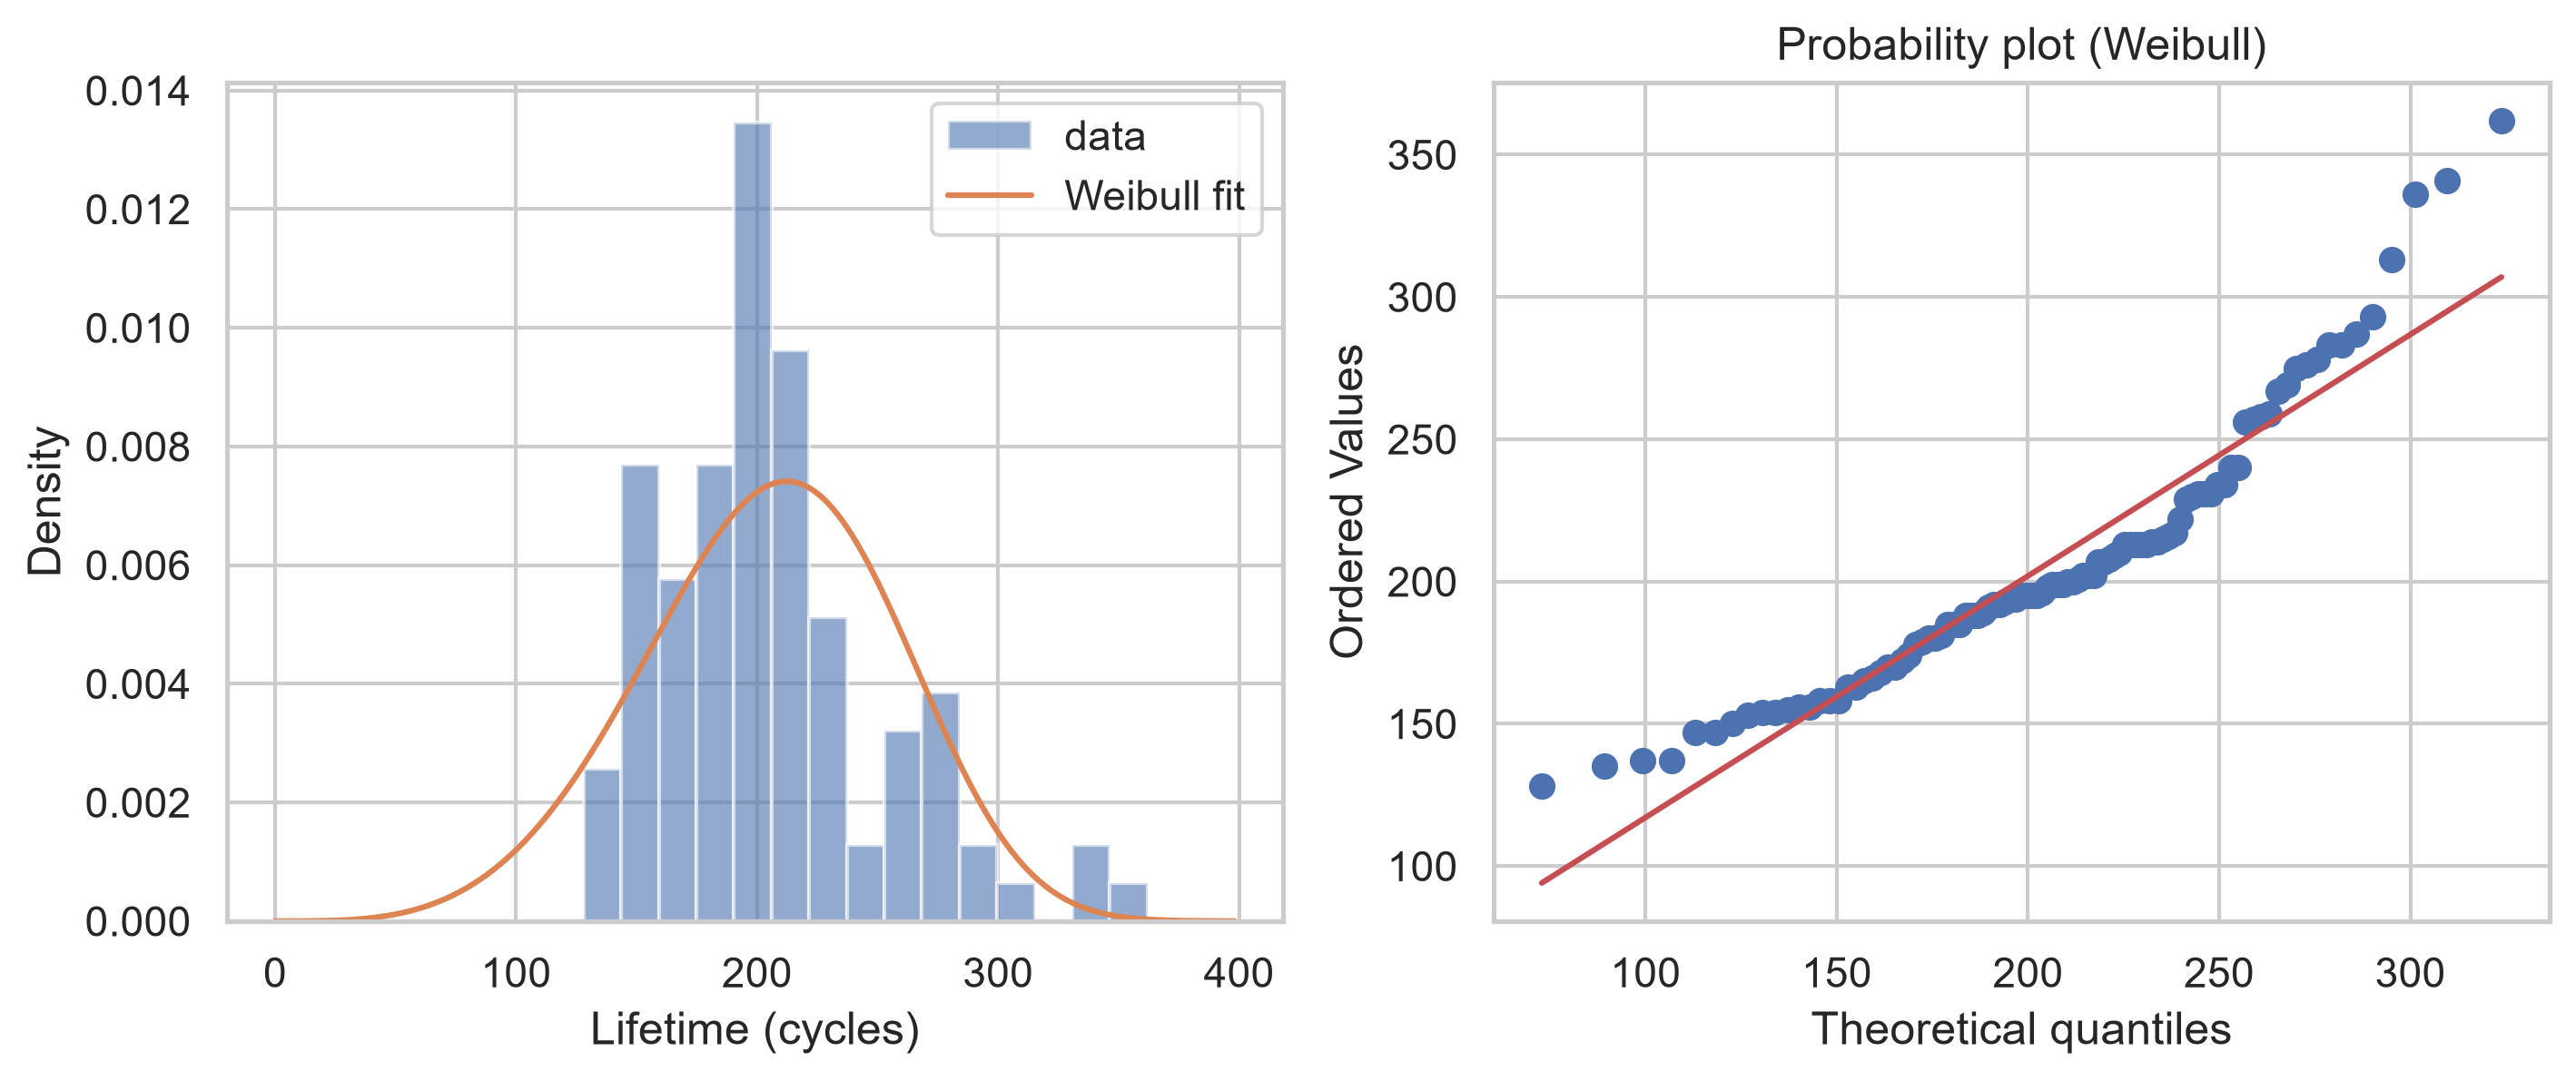

In [3]:
#| code-fold: false
beta, loc, eta = stats.weibull_min.fit(lifetimes, floc=0)
print(f"Weibull fit: shape beta = {beta:.2f}, scale eta = {eta:.1f} cycles")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
t = np.linspace(0, lifetimes.max() * 1.1, 300)
axes[0].hist(lifetimes, bins=15, density=True, alpha=0.6, label="data")
axes[0].plot(t, stats.weibull_min.pdf(t, beta, scale=eta), label="Weibull fit")
axes[0].set(xlabel="Lifetime (cycles)", ylabel="Density"); axes[0].legend()
stats.probplot(lifetimes, dist=stats.weibull_min, sparams=(beta, 0, eta), plot=axes[1])
axes[1].set_title("Probability plot (Weibull)")
plt.show()

**Discussion.** We fixed the location parameter at zero (`floc=0`), i.e. we use the two-parameter Weibull distribution. The estimated shape parameter is clearly larger than 1 – the engines show **wear-out behaviour**, as expected for a degradation simulation. The probability plot tells us whether the Weibull model is adequate over the whole range; pay particular attention to the lower tail, which determines the B10 life.

Note that no engine fails very early: the shortest lifetime is well above zero. A three-parameter Weibull distribution with a *failure-free time* (location parameter $t_0 > 0$) could describe this better – a question for Exercise 1.

In [4]:
#| code-fold: false
b10 = stats.weibull_min.ppf(0.10, beta, scale=eta)
print(f"B10 life from the fit:    {b10:.0f} cycles")
print(f"B10 from the formula:     {eta * (-np.log(0.9)) ** (1 / beta):.0f} cycles")
print(f"Empirical 10 % quantile:  {lifetimes.quantile(0.10):.0f} cycles")

B10 life from the fit:    135 cycles
B10 from the formula:     135 cycles
Empirical 10 % quantile:  155 cycles


## Confidence intervals

The mean lifetime we computed is an **estimate** from 100 engines. Another fleet of 100 engines would give a somewhat different value. A confidence interval quantifies this sampling uncertainty.

::: {.callout-note}
## Definition: Confidence interval
A 95 % **confidence interval** is computed from the data by a procedure that, if the experiment were repeated many times, would contain the true parameter in 95 % of the repetitions.

For the mean of approximately normal data (or large $n$ by the central limit theorem):
$$\bar x \pm t_{n-1,\,0.975}\,\frac{s}{\sqrt n},$$
where $t_{n-1,\,0.975}$ is the 97.5 % quantile of the t-distribution with $n-1$ degrees of freedom ($\approx 1.98$ for $n = 100$).
:::

![Twenty repetitions of the same experiment, each with its own 95 % confidence interval for the mean. On average, 19 of 20 intervals contain the true mean; here two miss it (red). For a single computed interval we never know whether it is one of the lucky ones.](images/ci-coverage.png){#fig-cicoverage width=90%}

::: {.callout-warning}
## Pitfall: what a confidence interval does *not* say
A computed interval, say [195, 215] cycles, does **not** contain the true mean "with 95 % probability" – in the classical view, the true mean is fixed and either inside or not. The 95 % refers to the reliability of the method. Also, a confidence interval for the *mean* says nothing about the spread of *individual* lifetimes: most single engines lie far outside it.
:::

For many quantities – the B10 life, a median, a ratio – there is no simple formula for the interval. The bootstrap solves this by simulation:

::: {.callout-note}
## Definition: Bootstrap
Draw $B$ (e.g. 10,000) samples of size $n$ **with replacement** from the observed data and compute the statistic of interest for each. The distribution of these bootstrap replicates approximates the sampling distribution of the statistic; its 2.5 % and 97.5 % quantiles give an approximate 95 % confidence interval (percentile method; SciPy uses the refined BCa method by default).
:::

In [5]:
#| code-fold: false
ci_t = stats.t.interval(0.95, df=len(lifetimes) - 1,
                        loc=lifetimes.mean(), scale=stats.sem(lifetimes))
boot = stats.bootstrap((lifetimes.values,), np.mean, confidence_level=0.95,
                       random_state=0)
print(f"Mean lifetime: {lifetimes.mean():.1f} cycles")
print("t-interval:        ", np.round(ci_t, 1))
print("bootstrap interval:", np.round(boot.confidence_interval, 1))

Mean lifetime: 206.3 cycles
t-interval:         [197.1 215.5]
bootstrap interval: [197.9 215.8]


**Discussion.** For the mean of 100 observations both methods give almost the same interval – the central limit theorem makes the t-interval reliable here. The bootstrap becomes valuable for statistics without a known formula (Exercise 2) and for small or strongly skewed samples.

## Back to the decision

The requirement "at most 10 % failures with 95 % confidence" has two parts. The 10 % defines the B10 life. The 95 % confidence means that we must not use the point estimate of B10 but a value that is, with 95 % confidence, *below* the true B10 – the lower bound of a one-sided 95 % confidence interval, which we obtain with the bootstrap. And preventive overhaul only makes sense if the failure rate increases with age, i.e. $\beta > 1$.

In [6]:
#| code-fold: false
def b10_of(x):
    c, _, scale = stats.weibull_min.fit(x, floc=0)
    return stats.weibull_min.ppf(0.10, c, scale=scale)

boot_b10 = stats.bootstrap((lifetimes.values,), b10_of, n_resamples=1000, confidence_level=0.90,
                           method="percentile", random_state=1)
b10_lower = boot_b10.confidence_interval.low      # lower end of a 90 % two-sided = 95 % one-sided bound
print(f"Weibull shape beta = {beta:.2f}  ->  {'wear-out: preventive overhaul is sensible' if beta > 1 else 'no wear-out: preventive overhaul does not help'}")
print(f"B10 point estimate: {b10:.0f} cycles, 95 % lower confidence bound: {b10_lower:.0f} cycles")
print(f"Decision: overhaul after {int(np.floor(b10_lower))} flight cycles at the latest.")

Weibull shape beta = 4.41  ->  wear-out: preventive overhaul is sensible
B10 point estimate: 135 cycles, 95 % lower confidence bound: 128 cycles
Decision: overhaul after 128 flight cycles at the latest.


The difference between the point estimate and the lower bound is the price of having data from only 100 engines – more data would allow a longer interval. In the real world, the decision would also consider that C-MAPSS is a *simulation*: before an interval is approved, the model would have to be validated against field data of real engines.

## Bayes' theorem: how much should we trust an alarm?

So far we have treated probabilities as long-run frequencies. **Conditional probabilities** describe how the probability of an event changes when we know that another event has occurred.

::: {.callout-important}
## Theorem: Bayes' theorem
For events $F$ and $A$ with $P(A) > 0$:
$$P(F \mid A) = \frac{P(A \mid F)\,P(F)}{P(A)} = \frac{P(A \mid F)\,P(F)}{P(A \mid F)\,P(F) + P(A \mid \bar F)\,P(\bar F)}.$$
$P(F)$ is the **prior** probability, $P(F \mid A)$ the **posterior** probability after observing $A$.
:::

Example: a condition monitoring system detects a bearing fault $F$ with probability $P(A \mid F) = 0.95$ (*sensitivity*) and raises a false alarm on a healthy bearing with probability $P(A \mid \bar F) = 0.05$. Only 1 % of the monitored bearings are actually damaged. If the system raises an alarm $A$, how likely is a real fault?

$$P(F \mid A) = \frac{0.95 \cdot 0.01}{0.95 \cdot 0.01 + 0.05 \cdot 0.99} \approx 0.16$$

Five out of six alarms are false – not because the system is bad, but because faults are rare.

::: {.callout-warning}
## Pitfall: base rate neglect
Intuition tends to confuse $P(A \mid F)$ ("the system detects 95 % of all faults") with $P(F \mid A)$ ("95 % of all alarms are real"). When the base rate $P(F)$ is small, the two differ dramatically. This effect returns in Chapter 7 as the *precision* of a classifier.
:::

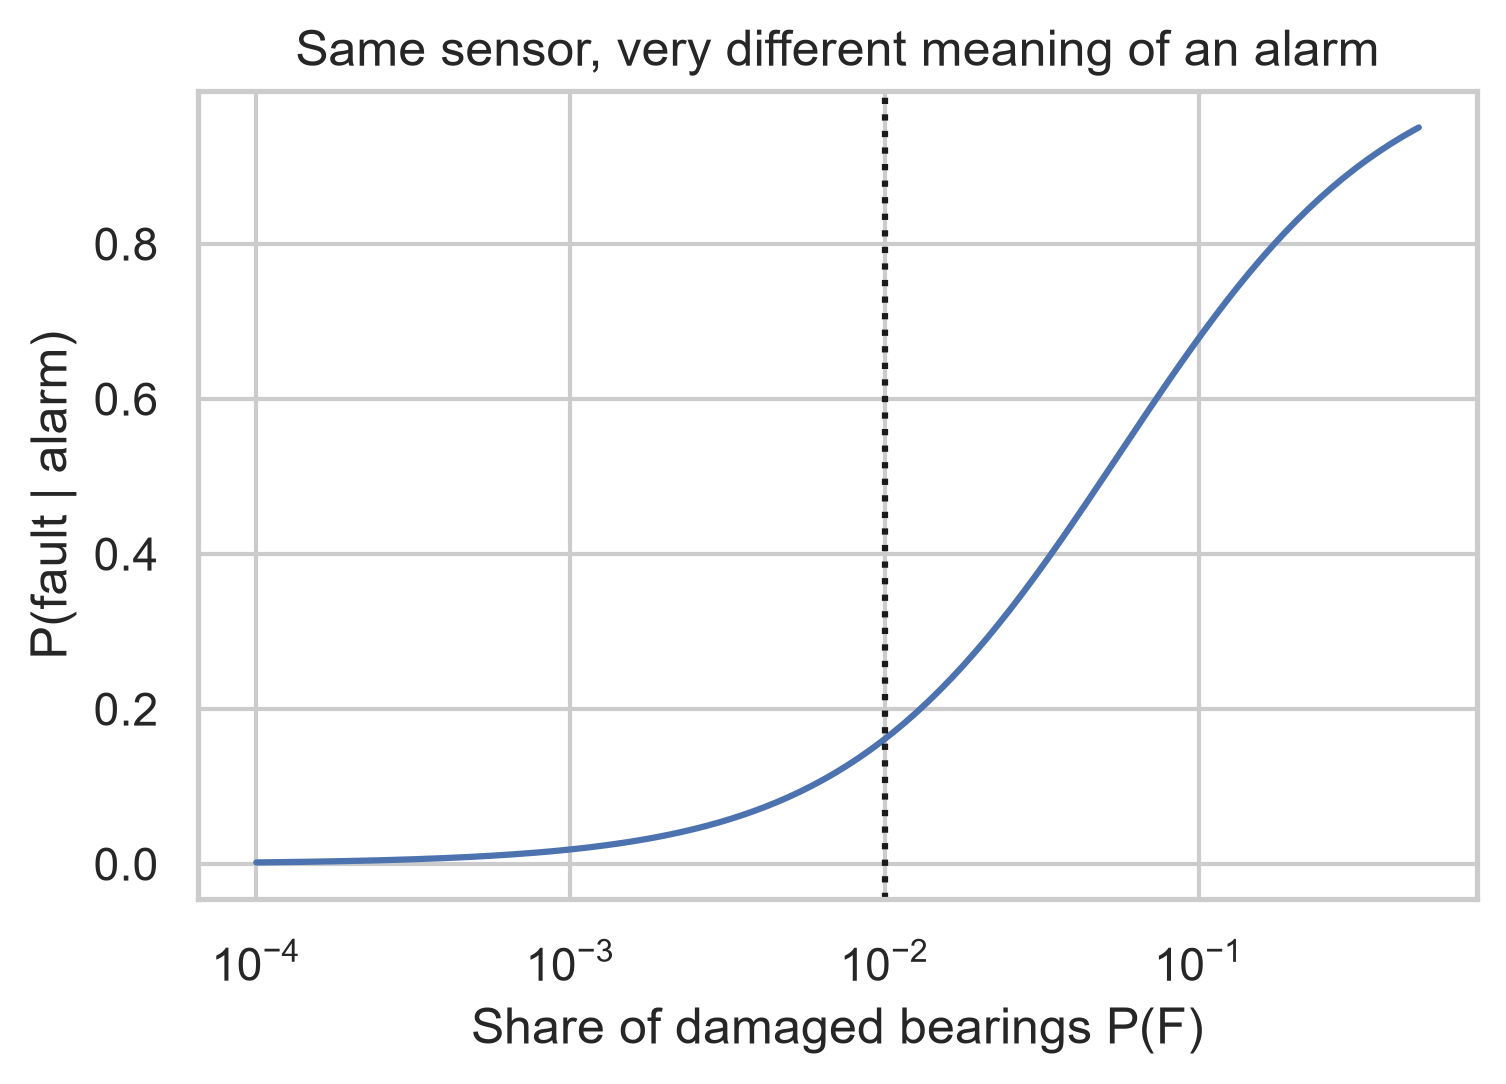

In [7]:
#| code-fold: false
sens, false_alarm = 0.95, 0.05
prevalence = np.logspace(-4, -0.3, 200)
posterior = sens * prevalence / (sens * prevalence + false_alarm * (1 - prevalence))

plt.semilogx(prevalence, posterior)
plt.axvline(0.01, ls=":", c="k")
plt.xlabel("Share of damaged bearings P(F)"); plt.ylabel("P(fault | alarm)")
plt.title("Same sensor, very different meaning of an alarm")
plt.show()

## Extension: Bayesian estimation with prior knowledge

*Extension – optional material, not required for the exam.*

Classical (frequentist) statistics uses only the current data. Bayesian statistics treats an unknown parameter $\theta$ itself as uncertain, describes the knowledge before the experiment by a **prior distribution** and updates it with the data to a **posterior distribution**:

$$p(\theta \mid \text{data}) \propto p(\text{data} \mid \theta)\; p(\theta).$$

This is attractive in engineering, where tests are expensive but experience from predecessor products exists. Example: a new product variant is tested, 3 of 50 parts are defective. From the predecessor product we know a defect rate of about 2 %.

For a proportion, the **beta distribution** is a convenient prior: with prior $\text{Beta}(a, b)$ and $k$ defects in $n$ parts, the posterior is again a beta distribution, $\text{Beta}(a + k,\; b + n - k)$. (We write $a, b$ for the beta parameters to avoid confusion with the Weibull shape $\beta$.) The prior mean is $a/(a+b)$, so $\text{Beta}(2, 98)$ has mean $2/(2+98) = 2\,\%$ and carries roughly the weight of 100 previously inspected parts.

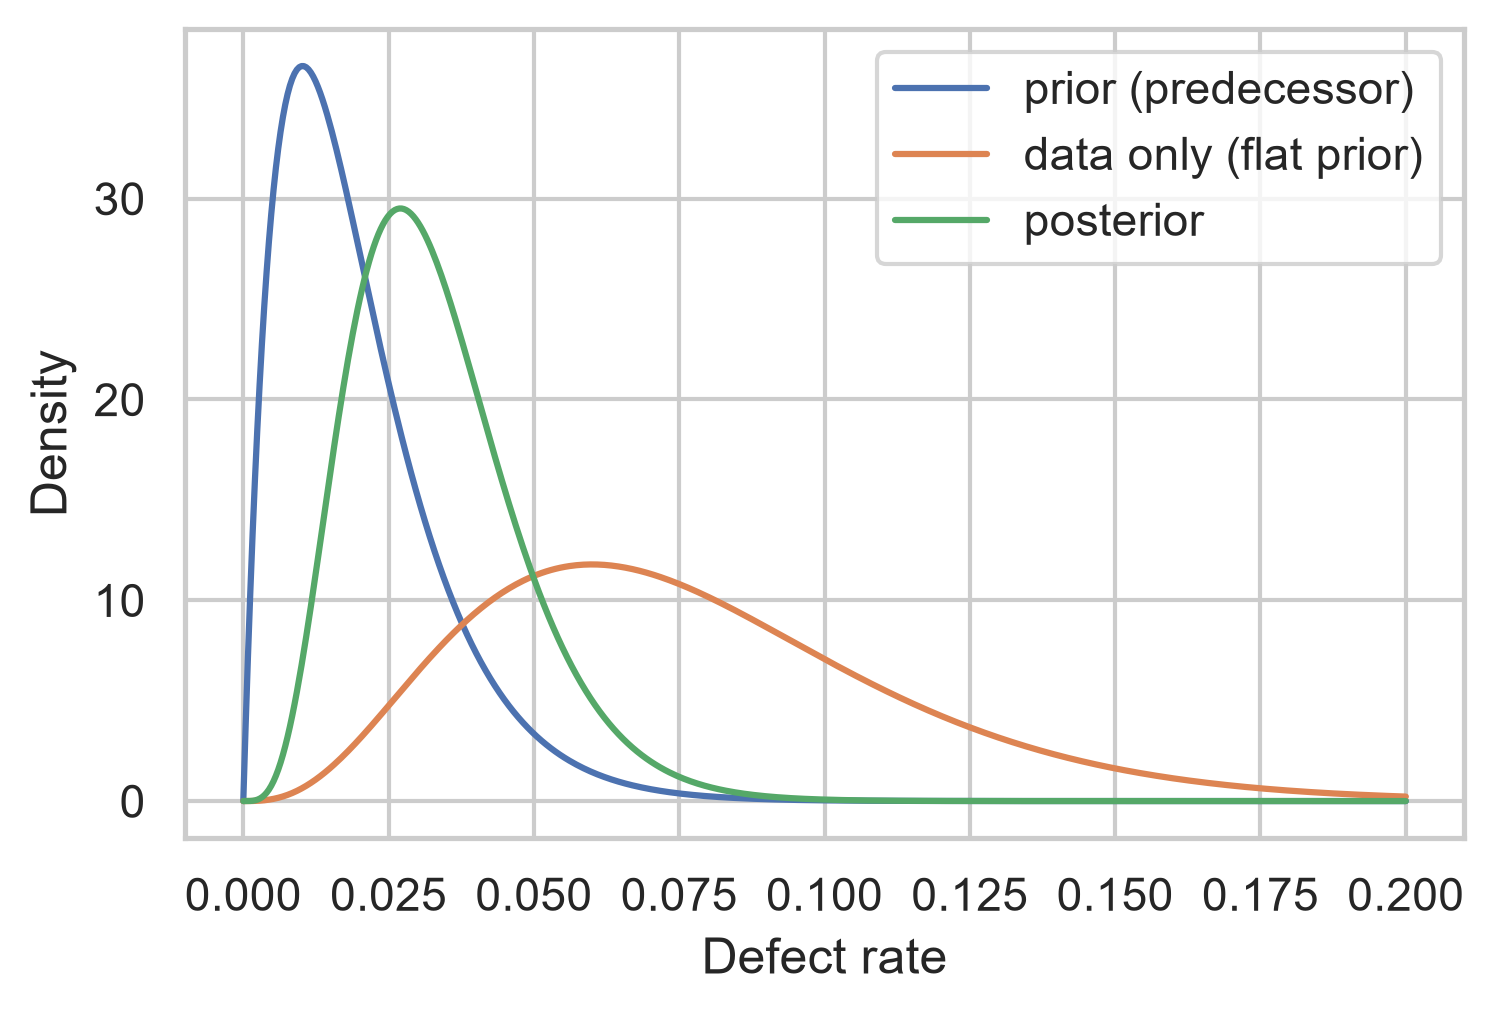

Frequentist: 6.0%, 95 % CI [1.3%, 16.5%]
Bayesian:    3.3%, 95 % credible interval [1.1%, 6.7%]


In [8]:
#| code-fold: false
k, n = 3, 50                       # new tests: defects, parts
a0, b0 = 2, 98                     # prior from the predecessor product
a1, b1 = a0 + k, b0 + n - k        # posterior

p = np.linspace(0, 0.20, 500)
plt.plot(p, stats.beta.pdf(p, a0, b0), label="prior (predecessor)")
plt.plot(p, stats.beta.pdf(p, 1 + k, 1 + n - k), label="data only (flat prior)")
plt.plot(p, stats.beta.pdf(p, a1, b1), label="posterior")
plt.xlabel("Defect rate"); plt.ylabel("Density"); plt.legend()
plt.show()

ci_freq = stats.binomtest(k, n).proportion_ci(0.95)
print(f"Frequentist: {k/n:.1%}, 95 % CI [{ci_freq.low:.1%}, {ci_freq.high:.1%}]")
lo, hi = stats.beta.interval(0.95, a1, b1)
print(f"Bayesian:    {a1/(a1+b1):.1%}, 95 % credible interval [{lo:.1%}, {hi:.1%}]")

**Discussion.** The posterior lies between prior and data: the new tests suggest a higher defect rate than the predecessor, but 50 parts are not enough to overrule the experience from 100 parts completely. The Bayesian **credible interval** has the intuitive interpretation that the classical confidence interval lacks: given prior and data, the defect rate lies in this interval with 95 % probability. The price is that the result depends on the prior – which must therefore be justified and documented. Whether the predecessor is really comparable is an engineering judgement, not a statistical one.

::: {.callout-important}
## Key takeaways
- Distributions are modelling choices; physics (sum, product, weakest link) guides the choice, probability plots check it.
- The Weibull shape parameter distinguishes early failures, random failures and wear-out – and decides whether preventive maintenance makes sense.
- Confidence intervals quantify the uncertainty of an estimate; the bootstrap provides them for almost any statistic.
- Bayes' theorem: with rare events, even good detectors produce mostly false alarms.
:::

## Exercises

<div class="exercises">

1. Fit a lognormal, a normal and a three-parameter Weibull distribution (free location parameter) to the lifetimes. Compare the fits with probability plots and the Kolmogorov–Smirnov statistic.
2. Use the bootstrap to compute a 95 % confidence interval for the B10 life. Why is it much wider (relative to the estimate) than the interval for the mean?
3. How does the width of the confidence interval of the mean change if only 20 engines are available? Simulate it by drawing many random subsamples of 20 engines.
4. Interpret the shape parameter for the maintenance strategy: does preventive replacement make sense? At which age would you replace an engine if at most 5 % of the engines may fail before replacement?
5. The fault share in a well-maintained fleet is only 0.1 %. How reliable is an alarm of the monitoring system above? Which false alarm rate would be needed to reach $P(F \mid A) = 50\,\%$?
6. (Extension) Repeat the defect-rate analysis with a weak prior Beta(0.2, 9.8) and a strong prior Beta(20, 980). When does the prior dominate, when the data?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

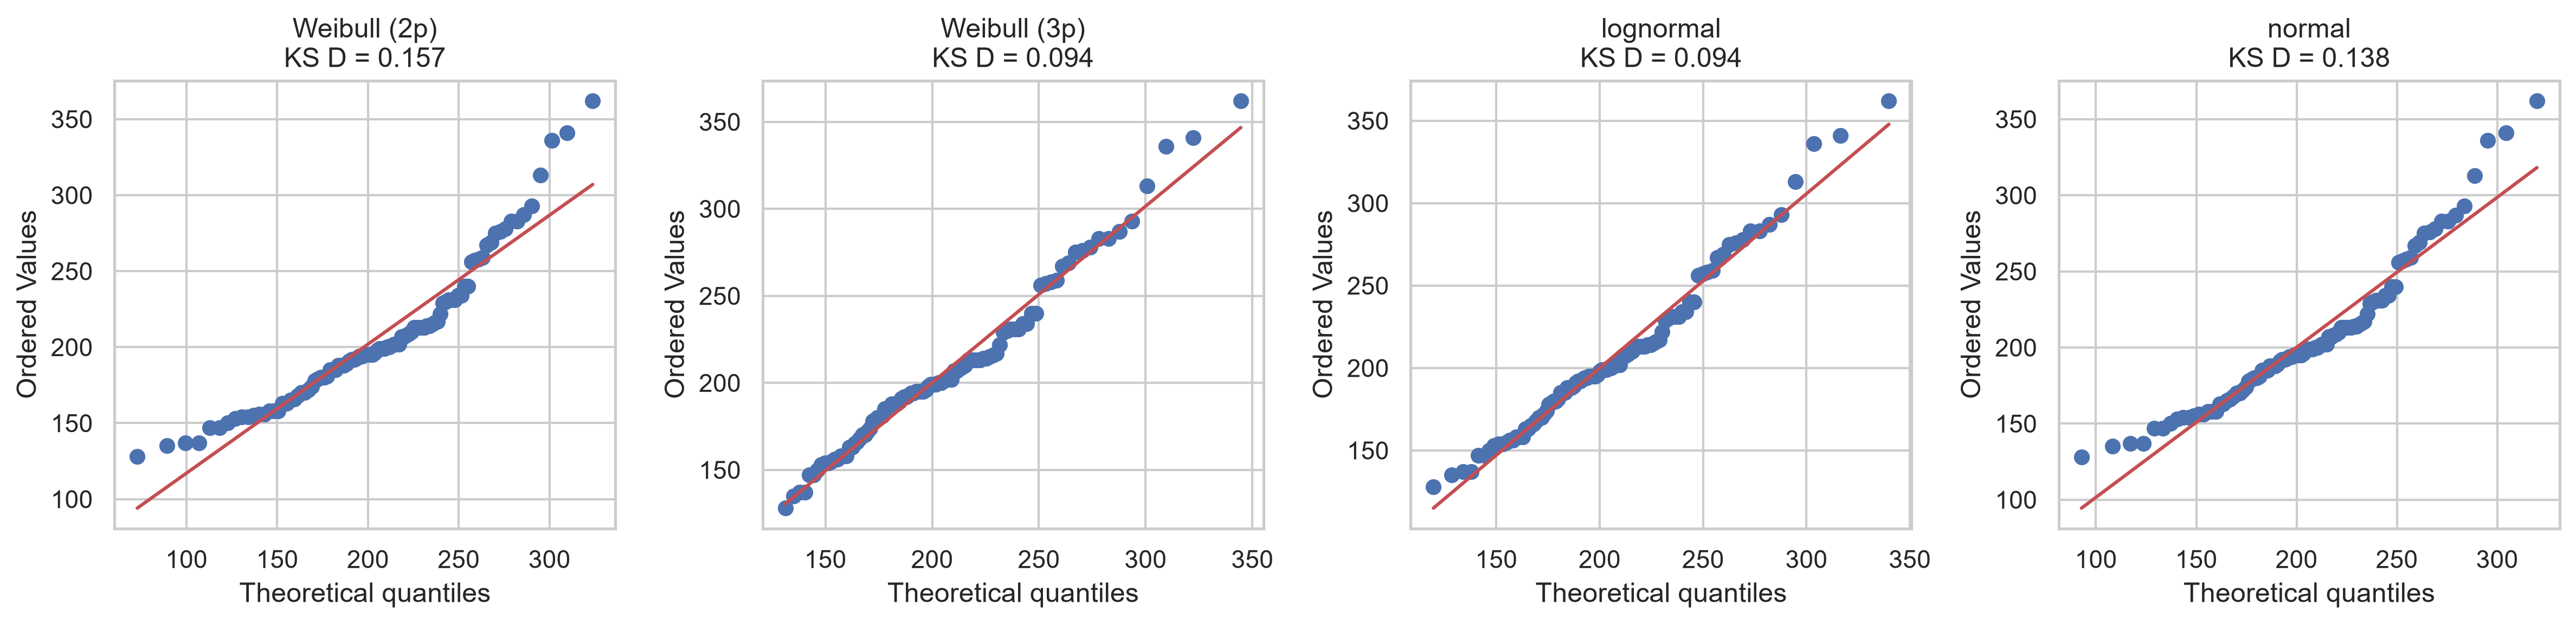

In [9]:
#| code-fold: false
fits = {
    "Weibull (2p)": (stats.weibull_min, stats.weibull_min.fit(lifetimes, floc=0)),
    "Weibull (3p)": (stats.weibull_min, stats.weibull_min.fit(lifetimes)),
    "lognormal":    (stats.lognorm, stats.lognorm.fit(lifetimes, floc=0)),
    "normal":       (stats.norm, stats.norm.fit(lifetimes)),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, (dist, params)) in zip(axes, fits.items()):
    stats.probplot(lifetimes, dist=dist, sparams=params, plot=ax)
    ks = stats.kstest(lifetimes, dist.cdf, args=params)
    ax.set_title(f"{name}\nKS D = {ks.statistic:.3f}")
plt.tight_layout(); plt.show()

The model with the smallest KS statistic and the straightest probability plot fits best. The three-parameter Weibull has one more parameter and therefore always fits at least as well as the two-parameter version; its location parameter estimates a failure-free time. Caution: the p-values of the KS test are not valid when the parameters were estimated from the same data, so use the statistic for comparison only. With 100 observations, several distributions usually fit acceptably – the choice should also be guided by physics (Weibull for wear-out).
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

In [10]:
#| code-fold: false
def b10_stat(x):
    c, _, scale = stats.weibull_min.fit(x, floc=0)
    return stats.weibull_min.ppf(0.10, c, scale=scale)

boot_b10 = stats.bootstrap((lifetimes.values,), b10_stat, n_resamples=1000,
                           method="percentile", random_state=0)
lo, hi = boot_b10.confidence_interval
print(f"B10 = {b10:.0f} cycles, 95 % CI [{lo:.0f}, {hi:.0f}]  (relative width {(hi - lo) / b10:.0%})")
print(f"Mean: relative width {(ci_t[1] - ci_t[0]) / lifetimes.mean():.0%}")

B10 = 135 cycles, 95 % CI [127, 146]  (relative width 14%)
Mean: relative width 9%


The B10 life is a statement about the **lower tail** of the distribution, where only about 10 of the 100 engines contribute information. In addition, it depends on two estimated parameters, and the shape parameter enters as an exponent. The mean uses all observations equally. Reliability figures in the tails are therefore always much more uncertain than averages – a reason for large safety factors.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [11]:
#| code-fold: false
rng = np.random.default_rng(0)
widths = []
for _ in range(2000):
    sub = rng.choice(lifetimes.values, size=20, replace=False)
    lo_, hi_ = stats.t.interval(0.95, df=19, loc=sub.mean(), scale=stats.sem(sub))
    widths.append(hi_ - lo_)
print(f"n = 100: width {ci_t[1] - ci_t[0]:.1f} cycles")
print(f"n = 20:  mean width {np.mean(widths):.1f} cycles (ratio {np.mean(widths) / (ci_t[1] - ci_t[0]):.2f})")

n = 100: width 18.4 cycles
n = 20:  mean width 42.6 cycles (ratio 2.32)


The width scales approximately with $1/\sqrt{n}$, so going from 100 to 20 engines should make the interval about $\sqrt{5} \approx 2.2$ times wider; the t-quantile for 19 degrees of freedom (2.09 instead of 1.98) adds a little more. (Subsampling without replacement from only 100 engines slightly reduces the spread, so the simulated ratio can be a bit smaller.)
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

In [12]:
#| code-fold: false
t05 = stats.weibull_min.ppf(0.05, beta, scale=eta)
print(f"beta = {beta:.2f} > 1 -> wear-out; replacement age for 5 % failures: {t05:.0f} cycles")

beta = 4.41 > 1 -> wear-out; replacement age for 5 % failures: 115 cycles


Since $\beta > 1$, the failure rate increases with age, so preventive replacement reduces failures. The replacement age for at most 5 % failures is the 5 % quantile $B_5 = \eta(-\ln 0.95)^{1/\beta}$. Given the large uncertainty of tail estimates (Exercise 2), one would in practice use the lower confidence bound of $B_5$ rather than the point estimate. Whether replacement is economical depends additionally on the cost ratio of planned replacement and unplanned failure.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5
With $P(F) = 0.001$:
$$P(F \mid A) = \frac{0.95 \cdot 0.001}{0.95 \cdot 0.001 + 0.05 \cdot 0.999} \approx 0.019,$$
i.e. only about 2 % of the alarms are real. For $P(F \mid A) = 0.5$ we need $0.95 \cdot 0.001 = q \cdot 0.999$, where $q = P(A \mid \bar F)$ is the false alarm rate, so $q \approx 0.00095$ – roughly one false alarm per thousand healthy bearings. The better the fleet, the more specific the monitoring must be.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 6

In [13]:
#| code-fold: false
for name, (a, b) in {"weak": (0.2, 9.8), "medium": (2, 98), "strong": (20, 980)}.items():
    post = stats.beta(a + k, b + n - k)
    lo_, hi_ = post.interval(0.95)
    print(f"{name:6s} prior: posterior mean {post.mean():.1%}, 95 % credible interval [{lo_:.1%}, {hi_:.1%}]")

weak   prior: posterior mean 5.3%, 95 % credible interval [1.2%, 12.2%]
medium prior: posterior mean 3.3%, 95 % credible interval [1.1%, 6.7%]
strong prior: posterior mean 2.2%, 95 % credible interval [1.4%, 3.2%]


All three priors have a mean of 2 % but different weights ($a + b$ = 10, 100, 1000 "virtual parts"). The weak prior is dominated by the 50 real parts: the posterior mean is close to the observed 6 %. The strong prior hardly moves – 50 parts are not enough to overrule 1,000 virtual ones. Rule of thumb: the data dominate once $n$ is large compared with $a + b$.
:::